# 01 · Exploratory analysis

Business question: can we tell at purchase time which orders will arrive late, so the promised date can be adjusted or the shipment prioritized, and negative reviews avoided?

Before modeling I check four things:
- size and balance of the target;
- how delays change over time;
- how much they affect the rating;
- which variables are related to them.

The base table comes from PostgreSQL (`sql/05_export_model_base.sql`). The aggregate figures come from `sql/04_analysis.sql`.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

from features import load_model_base
from plot_style import AQUA, BLUE, GRAY, INK_2, ORANGE, apply_style

apply_style()
FIG_DIR = "../reports/figures"
SQL_DIR = "../reports/sql_results"

df = load_model_base("../data/processed/model_base.csv")
print(f"Orders with a known delivery outcome: {len(df):,}")
print(f"Purchase period: {df.purchase_ts.min():%Y-%m-%d} to {df.purchase_ts.max():%Y-%m-%d}")

Orders with a known delivery outcome: 97,300
Purchase period: 2017-01-05 to 2018-08-29


## 1. Target balance

`is_late = 1` when the order did not arrive on time:
- late: it was delivered after the promised day;
- not_delivered: it was shipped but never recorded a delivery, and by the end of the data it was already past its promised date.

In [2]:
balance = (
    df.groupby("delivery_status")
    .size()
    .rename("orders")
    .to_frame()
    .assign(percent=lambda t: (100 * t.orders / t.orders.sum()).round(2))
    .sort_values("orders", ascending=False)
)
print(f"Share of orders not delivered on time: {df.is_late.mean():.2%}")
balance

Share of orders not delivered on time: 7.84%


,orders,percent
delivery_status,,
on_time,89672,92.16
late,6531,6.71
not_delivered,1097,1.13


The classes are highly imbalanced: fewer than 8% of orders arrive late. A model that said "there is never a delay" would be 92% accurate and completely useless. So instead of accuracy, I measure what share of late orders is caught by reviewing a fixed share of orders, with AUC-PR as a supporting metric.

## 2. Delays change a lot over time

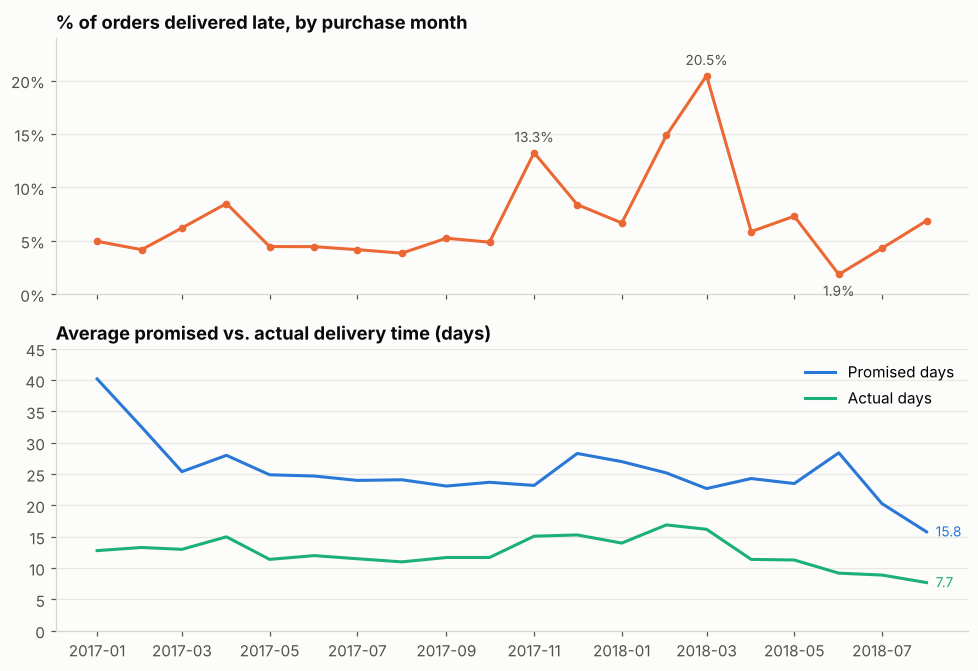

In [3]:
monthly = pd.read_csv(f"{SQL_DIR}/q1_monthly_kpis.csv", parse_dates=["month"])
monthly["late_pct"] = 100 - monthly["on_time_pct"]

fig, axes = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True, gridspec_kw={"height_ratios": [1, 1.1]})
ax = axes[0]
ax.plot(monthly.month, monthly.late_pct, color=ORANGE, marker="o", markersize=4)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("% of orders delivered late, by purchase month")
for m, dy in [("2017-11-01", 7), ("2018-03-01", 7), ("2018-06-01", -14)]:
    r = monthly[monthly.month == m].iloc[0]
    ax.annotate(f"{r.late_pct:.1f}%", (r.month, r.late_pct), textcoords="offset points",
                xytext=(0, dy), ha="center", color=INK_2, fontsize=9)
ax.set_ylim(0, 24)

ax = axes[1]
ax.plot(monthly.month, monthly.avg_promised_days, color=BLUE, label="Promised days")
ax.plot(monthly.month, monthly.avg_actual_days, color=AQUA, label="Actual days")
ax.set_title("Average promised vs. actual delivery time (days)")
ax.legend(loc="upper right")
ax.set_ylim(0, 45)
for line, col in [("avg_promised_days", BLUE), ("avg_actual_days", AQUA)]:
    last = monthly.iloc[-1]
    ax.annotate(f"{last[line]:.1f}", (last.month, last[line]), textcoords="offset points",
                xytext=(6, -3), color=col, fontsize=9)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/01_monthly_late_and_promise.png", dpi=160)

Three things in this chart shape all of the modeling:

1. There was a spike in delays in November 2017 (Black Friday) and a bigger one in February and March 2018. In those months actual delivery took longer, but the promised time did not.
2. From mid-2018, Olist promised shorter and shorter delivery times (from ~24 to ~16 days), while deliveries were also getting faster.
3. As a result, a model trained on 2017 and early 2018 is evaluated in a period with different rules. That is why validation is time-based and I also run a month-by-month backtest.

## 3. How much delays hurt the rating

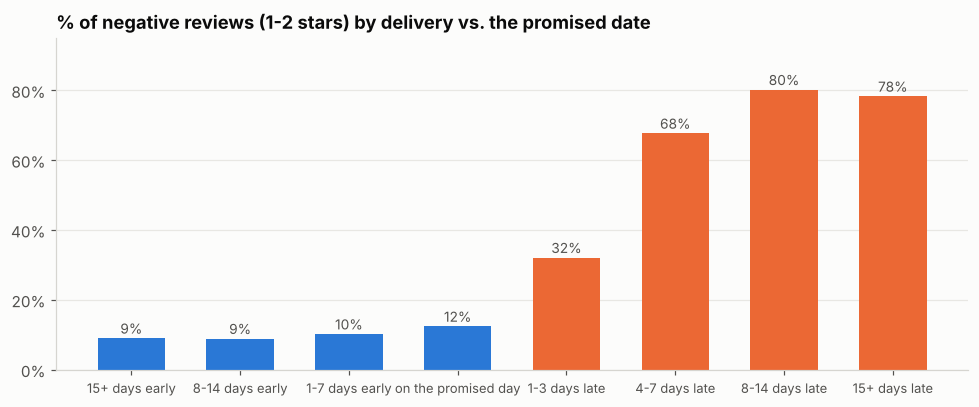

,value
total_reviews,96584.0
total_negatives,12939.0
late_reviews,7402.0
late_negatives,4692.0
neg_rate_on_time_pct,9.2
neg_rate_late_pct,63.4
excess_negatives_from_delays,4008.0
excess_share_of_all_negatives_pct,31.0


In [4]:
by_days = pd.read_csv(f"{SQL_DIR}/q3_review_by_days_late.csv")
by_days["label"] = by_days.bucket.str[4:]
colors = [BLUE if "early" in b or "promised" in b else ORANGE for b in by_days.bucket]

fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.bar(by_days.label, by_days.negative_pct, color=colors, width=0.62)
for b, v in zip(bars, by_days.negative_pct):
    ax.annotate(f"{v:.0f}%", (b.get_x() + b.get_width() / 2, v), textcoords="offset points",
                xytext=(0, 3), ha="center", fontsize=9, color=INK_2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("% of negative reviews (1-2 stars) by delivery vs. the promised date")
ax.tick_params(axis="x", labelsize=8.5)
ax.set_ylim(0, 95)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/02_negative_reviews_by_days_late.png", dpi=160)

attribution = pd.read_csv(f"{SQL_DIR}/q4_negative_reviews_attribution.csv").T.rename(columns={0: "value"})
attribution

When the order arrives on time, only ~9% of reviews are negative. With 1 to 3 days of delay the share rises to 32%, and with 4 or more days it goes above 67%.

In total, delays account for about 4,000 extra negative reviews, 31% of all negative reviews in the period. It is a problem worth tackling.

## 4. What is related to delays?

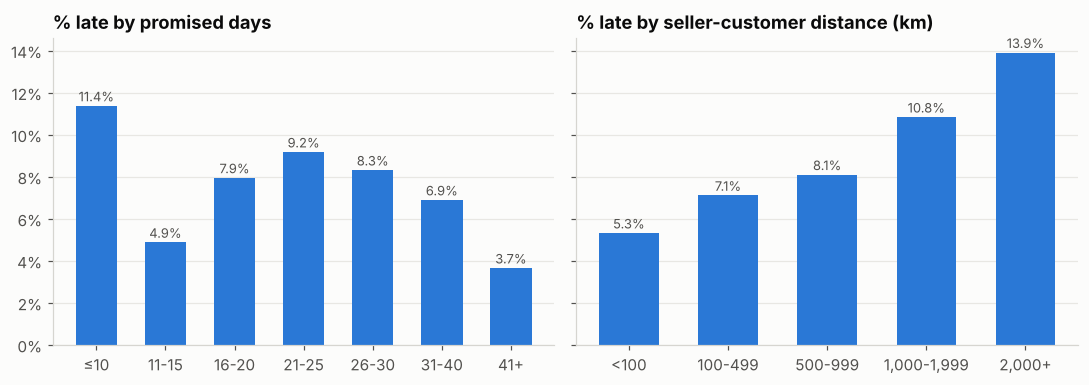

In [5]:
df["promise_bucket"] = pd.cut(df.promised_days, [0, 10, 15, 20, 25, 30, 40, 200],
                              labels=["≤10", "11-15", "16-20", "21-25", "26-30", "31-40", "41+"])
df["distance_bucket"] = pd.cut(df.max_distance_km, [-1, 100, 500, 1000, 2000, 5000],
                               labels=["<100", "100-499", "500-999", "1,000-1,999", "2,000+"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, col, title in [(axes[0], "promise_bucket", "Promised days"),
                       (axes[1], "distance_bucket", "Seller-customer distance (km)")]:
    rate = df.groupby(col, observed=True).is_late.mean() * 100
    ax.bar(rate.index.astype(str), rate.values, color=BLUE, width=0.6)
    for i, v in enumerate(rate.values):
        ax.annotate(f"{v:.1f}%", (i, v), textcoords="offset points", xytext=(0, 3),
                    ha="center", fontsize=8.5, color=INK_2)
    ax.set_title(f"% late by {title.lower()}")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
fig.tight_layout()

Distance raises the risk, as expected. The promised time on its own, however, barely separates late orders, because long promised times happen precisely on long routes.

What matters is the buffer: the promised time compared with how long that route usually takes. I build that variable in notebook 02.

In [6]:
states = pd.read_csv(f"{SQL_DIR}/q5_by_customer_state.csv")
states[["late_rank", "state", "orders", "late_pct", "avg_promised_days", "avg_actual_days", "avg_distance_km", "avg_review"]].head(8)

,late_rank,state,orders,late_pct,avg_promised_days,avg_actual_days,avg_distance_km,avg_review
0,1,AL,405,23.2,33.0,24.5,1830,3.79
1,2,MA,730,19.5,30.9,21.5,2105,3.79
2,3,SE,341,17.6,31.2,21.4,1651,3.84
3,4,CE,1310,16.3,31.7,21.2,2188,3.89
4,5,PI,482,15.1,30.6,19.4,1958,3.97
5,6,RJ,12598,14.2,26.9,15.2,490,3.92
6,7,BA,3321,14.0,30.0,19.3,1347,3.90
7,8,PA,961,13.0,37.7,23.7,2283,3.87


Rio de Janeiro (RJ) is a telling case: it is close to the sellers (490 km on average), but it has 14% late orders, almost three times São Paulo. Distance does not explain everything; the specific route matters. That is why I compute history by route (seller state → customer state).

In [7]:
pareto = pd.read_csv(f"{SQL_DIR}/q6_seller_pareto.csv")
share_50 = pareto.loc[pareto.cum_late_share_pct >= 50, "cum_sellers_pct"].iloc[0]
share_80 = pareto.loc[pareto.cum_late_share_pct >= 80, "cum_sellers_pct"].iloc[0]
print(f"{share_50:.1f}% of sellers account for 50% of late orders.")
print(f"{share_80:.1f}% of sellers account for 80%.")

3.4% of sellers account for 50% of late orders.
13.9% of sellers account for 80%.


## 5. Data quality

In [8]:
quality = pd.DataFrame({
    "nulls": df.isna().sum(),
    "% nulls": (100 * df.isna().mean()).round(2),
})
quality[quality.nulls > 0]

,nulls,% nulls
delivered_ts,1097,1.13
review_score,716,0.74
days_vs_estimate,1097,1.13
max_distance_km,486,0.50
customer_lat,273,0.28
customer_lng,273,0.28
main_photos_qty,1380,1.42
total_weight_g,16,0.02
total_volume_cm3,16,0.02
distance_bucket,486,0.50


What I found:

- Outcome columns: `delivered_ts`, `days_vs_estimate` and `review_score` are only missing where it makes sense (undelivered orders or orders without a review). They never enter the model as features.
- Distance: missing for ~0.5% of orders, because the zip code does not appear in the geolocation table. The model imputes it with the median or handles it natively.
- Zip codes: customer and seller zip codes came without leading zeros; this was fixed in SQL with `LPAD` (see `sql/03_star_schema.sql`).
- Estimated date: always 00:00, so delays are measured by calendar day.